# 06-串口、DMA与通信模块

> 先把电平变成字节，再把字节变成完整消息；用中断和 DMA 搬运数据，让主循环负责理解数据。

这是「嵌入式单片机一套通关」十二篇笔记的第 06 篇，承接第 05 篇的中断、共享变量与定时节拍。本篇串起 **USART → 接收缓冲区 → 消息解析 → DMA → 蓝牙/GPS 模块**，为后续传感器、存储和界面建立通信基础。

学完应能独立说明：两端怎样接线与匹配参数？RBNE、IDLE、TBE、TC 分别表示什么？DMA 的地址、方向、长度和请求映射怎样设置？连续数据如何在不越界、不误判消息的前提下交给业务？


## 1. 本篇范围与资料说明

| 课程分组 | 整理重点 |
|---|---|
| 04-串口通信 | UART/USART、引脚与 AF、发送、接收、模板、多文件封装 |
| 07-DMA直接内存访问 | 内存到内存、内存到外设、外设到内存、请求映射 |
| 通信设备 | JDY-33 蓝牙透传、NEO6M 页面中的 GPS/NMEA 解析 |
| 官方手册 | USART 标志和清除顺序、DMA 请求/计数/模式/停止语义 |

来源是[用户提供的知识库](https://www.yuque.com/embheima/mcu)，现跳转至[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。本篇已阅读上述 **14 个课程页面的可访问正文**，核对部分可见短代码，以及 GD32F4xx User Manual 3.4 的 USART、DMA 相关完整页；来源索引在第 32 节。

示例环境：GD32F407VET6、匹配的 GD32F4xx SPL/CMSIS、C99；调试串口使用课程板的 USART0/PA9/PA10，核心 LED 使用 PB2 高电平点亮。其他模组必须核对自己的板线、固件版本、电源和 I/O 电平。

代码、环形缓冲区、协议规则、自绘图和练习为重写的学习补充。网页长代码编辑器并未完整展开，课程完整 SDK 工程和模块附件没有下载。本次没有编译芯片工程、烧录或测量硬件波形；下文明确区分可复核的理论值、函数片段、工程整合示例与真实验收。


## 2. 先分清 UART、USART、逻辑电平与 RS-232/485

| 名称 | 解决什么问题 | 本篇用法 |
|---|---|---|
| UART | 异步串行收发，不传送单独时钟线 | TX/RX、起始位、数据位、停止位 |
| USART | 支持同步和异步的收发外设 | 本篇配置为异步 UART 模式 |
| 3.3 V 逻辑电平 UART | 引脚高低电平如何表达 0/1 | MCU 与合适电平的 USB-TTL/模块连接 |
| RS-232 | 电气接口，通常使用正负电压并有反相关系 | 需要收发器，不能直接接 MCU UART |
| RS-485 | 差分电气接口，常用于总线 | 需要差分收发器和方向/终端设计 |
| 应用协议 | 字节怎样组成命令/数据包 | 换行命令、NMEA、带长度和校验的数据帧 |

UART、USART 和 RS-232/485不处在同一层。一个 USART 外设可以经过合适收发器承载 RS-485 通信；Modbus 等应用协议还定义地址、功能码与校验。

异步不是“没有时钟”：发送端和接收端各自有时钟，只是不把时钟线一并传送。每个字符的起始沿重新建立采样基准。UART 支持的有效数据位数依硬件而定，不是“一次最多只能传 8 位”；本篇选择常用 8 位配置。

连接长度与速率取决于收发器、布线、终端、噪声和标准条件，不能把“RS-232 一定 30 m、RS-485 一定 1 km”当作任意项目的保证。


## 3. 接线：TX 接对方 RX，先确认逻辑电平

```text
MCU PA9  / USART0_TX ──→ USB-TTL RX
MCU PA10 / USART0_RX ←── USB-TTL TX
MCU GND              ── USB-TTL GND
```

课程发送、接收页明确纠正了原理图：**PA9/PA10 实际对应 USART0，图中的 USART1 标注有误；二者均选择 AF7。**“串口 1”这种板级口语编号不能代替芯片外设名。DAPLink 接入电脑后，调试下载接口和虚拟 COM 串口是不同功能，COM 号以电脑实际枚举结果为准。

| 核对项 | 正确做法 |
|---|---|
| 电平 | 匹配 MCU 的 3.3 V I/O 与外部设备电平；不要直接接 RS-232 正负电压 |
| 电源 | 模块底板有稳压器不代表 RX/TX 能接 5 V，电源和信号分别核对 |
| 地线 | 普通非隔离 UART 需要共同参考地 |
| TX/RX | 从各设备自身方向理解，TX 对 RX |
| 驱动冲突 | 同一 MCU RX 不应同时接 USB-TTL TX 和另一个模块 TX |
| 引脚复用 | GPIO 模式、AF 编号、封装引脚和实际板线全部匹配 |

UART 通常为点对点。用两组独立 USART 做“电脑 ↔ MCU ↔ 蓝牙”桥接，可避免两个发送器共同驱动一根线；课程也采用这种架构。


## 4. 8N1 字符帧与 0x55 时序

`115200, 8N1` 表示 115200 baud、8 个有效数据位、无校验、1 个停止位。普通非反相 UART 空闲为高：

```text
空闲 1 → 起始 0 → d0 d1 d2 d3 d4 d5 d6 d7 → 停止 1
```

LSB 先发时，`0x55 = 01010101₂` 的线上数据位次序为 `1,0,1,0,1,0,1,0`。

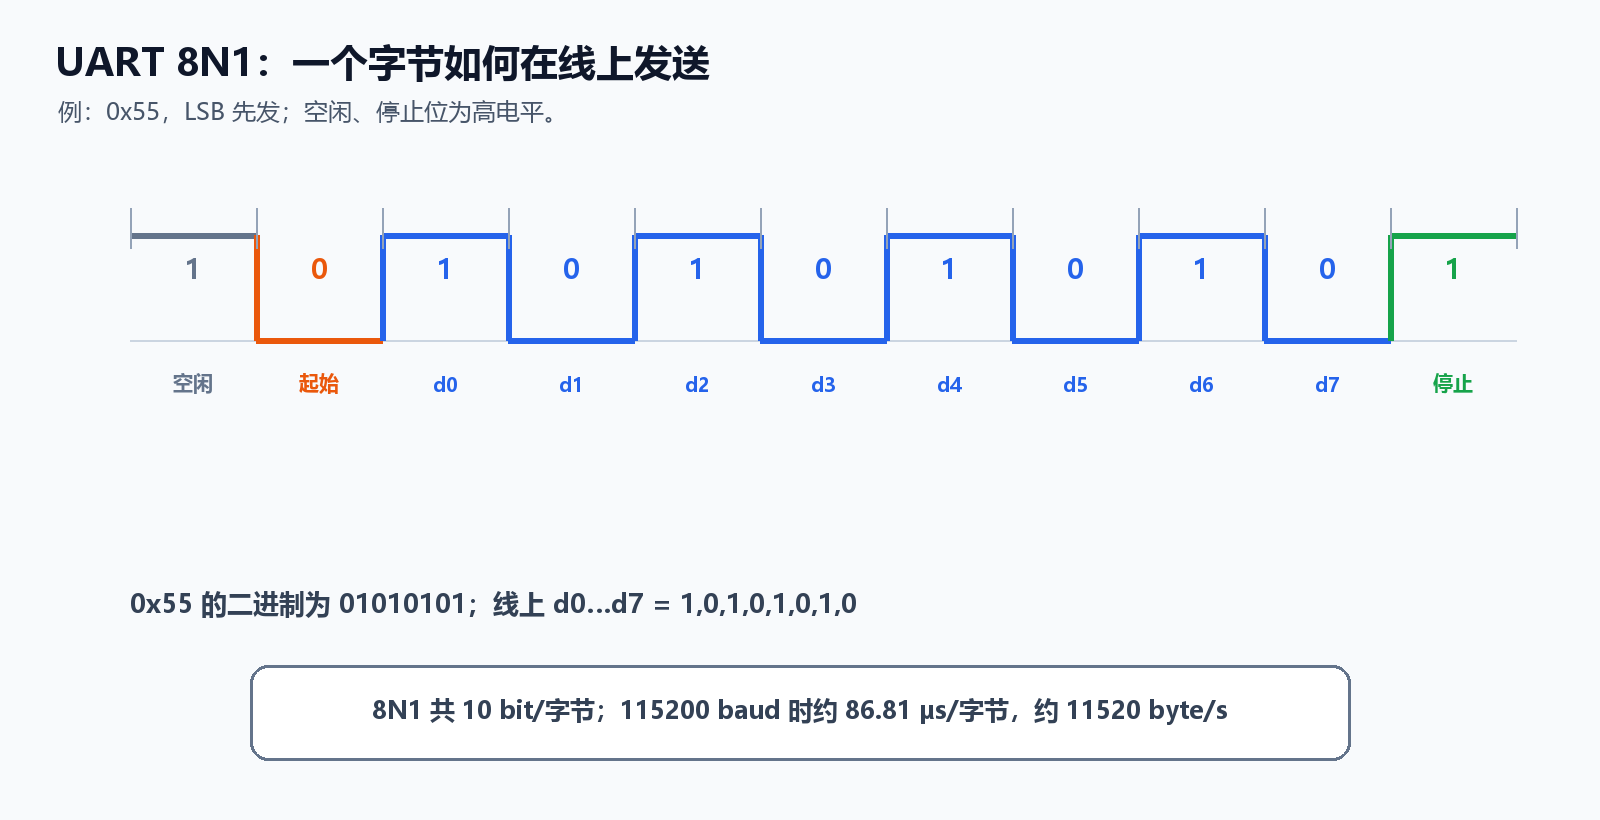

不要把“一个 UART 字符帧”和“应用的一条消息”混为一谈：`ON\n` 是 3 个字节、3 个字符帧，应用协议规定它们一起构成开灯命令。


## 5. 波特率、有效吞吐量与时间预算

普通二电平 UART 每个符号表达 1 bit，因此波特率数值等于线路比特率；更一般的调制并不一定如此。8N1 每个有效字节需要 `1+8+1=10` 个线路 bit：

```text
T_bit   = 1 / baud
T_byte  = 10 / baud                  （8N1）
R_byte  = baud / 10                  （连续发送，无额外间隙）
T_block = 字节数 × 10 / baud
```

| 算例 | 理论结果 |
|---|---:|
| 115200 baud，1 bit | 8.6806 µs |
| 115200 baud，1 个 8N1 字节 | 86.8056 µs |
| 115200 baud，连续有效吞吐 | 11520 byte/s |
| 115200 baud，1024 字节 | 约 88.889 ms |
| 9600 baud，1 个 8N1 字节 | 约 1.0417 ms |
| 9600 baud，80 字节 NMEA 文本 | 约 83.333 ms |

以上不含发送间隔、软件等待、蓝牙链路开销等。DMA 减少 CPU 搬运工作，不会把 115200 baud 的线速变大；`GPIO_OSPEED_50MHZ` 也只是 GPIO 边沿速度档位。


## 6. 校验位、有效数据位与波特率时钟

偶校验使“数据位加校验位”的 1 总数为偶数；奇校验则为奇数。`0x55` 有 4 个 1，偶校验位为 0、奇校验位为 1。奇偶校验能发现部分错误，不能替代完整报文校验，也不能检测所有多 bit 错误。

GD32F4xx 的 `WL` 字长包含被校验位占用的位置。手册 19.3.1/19.4.2 说明启用校验后最高一位由校验位替代：**想要 8 个有效数据位加校验，需要 9 位字长；8 位字长加校验通常只剩 7 个有效数据位。**两端工具里的“8E1”与底层寄存器字长要按这种语义对应。

USART 波特率由外设时钟 `UCLK`、过采样模式和分频寄存器共同决定。过采样 16 时：

```text
USARTDIV = UCLK / (16 × baud)
实际 baud = UCLK / (16 × 已量化的 USARTDIV)
```

如果 USART0 所用 UCLK 已确认是 84 MHz，目标 115200，则 USARTDIV≈45.5729；取最近的 1/16 分频得到 45.5625，等效除数 729，实际约 115226.34 baud，误差约 +0.0229%。这是算例，不代表本地模板的时钟已经测量过。

USART0 在 APB2，USART1/2 等在对应的 APB 总线；第 05 篇 TIMERSEL 倍频规则不能套到 USART。优先使用匹配库的 `usart_baudrate_set()`，并确认晶振、RCU 与时钟变量准确。没有必要手工硬写上面的算例寄存器值。


## 7. USART0 初始化：引脚、参数、收发与总开关

下面是独立实验的函数片段，需要 `gd32f4xx.h` 和匹配 SPL；将 `gd32f4xx_usart.c`、GPIO、RCU、MISC 等加入工程。先配置好参数，再使能外设：

```c
static void usart0_init_115200(void)
{
    NVIC_DisableIRQ(USART0_IRQn);
    rcu_periph_clock_enable(RCU_GPIOA);
    rcu_periph_clock_enable(RCU_USART0);

    gpio_mode_set(GPIOA, GPIO_MODE_AF, GPIO_PUPD_NONE,
                  GPIO_PIN_9 | GPIO_PIN_10);
    gpio_af_set(GPIOA, GPIO_AF_7, GPIO_PIN_9 | GPIO_PIN_10);
    gpio_output_options_set(GPIOA, GPIO_OTYPE_PP,
                            GPIO_OSPEED_50MHZ, GPIO_PIN_9);
    // RX 方向由 USART 控制，设置为 AF 不是让它主动驱动线路

    usart_deinit(USART0);
    usart_baudrate_set(USART0, 115200U);
    usart_word_length_set(USART0, USART_WL_8BIT);
    usart_parity_config(USART0, USART_PM_NONE);
    usart_stop_bit_set(USART0, USART_STB_1BIT);
    usart_data_first_config(USART0, USART_MSBF_LSB);
    usart_transmit_config(USART0, USART_TRANSMIT_ENABLE);
    usart_receive_config(USART0, USART_RECEIVE_ENABLE);
    usart_enable(USART0);
}
```

本函数尚未打开 RX IRQ；第 12 节再启用。初始化期间发送端应保持静默，或由应用明确丢弃启动阶段字节。波特率、字长、校验和停止位不得在正在传输时随意改写。

开启 GPIO 时钟、开启 USART 时钟、允许收发、开启 USART 总开关和开启 NVIC IRQ 是不同层次；其中一层缺失都可能导致通信失效。


## 8. TBE 与 TC：什么时候可以写，什么时候线真的空了

| 标志 | 含义 | 应用动作 |
|---|---|---|
| TBE | 发送数据缓冲区空，可放下一个字节 | 连续发送前等待 TBE |
| TC | 当前数据及发送缓冲已发完，包含尾部停止位 | 切 RS-485 方向、关 USART、进低功耗前等待 |
| DMA FTF | DMA 这次搬运达到完成/停止条件 | 不能直接当成 TX 引脚最后一位完成 |

发送器有数据缓冲和移位寄存器，TBE 置位时移位寄存器仍可能在发前一个字节。连续发送应利用这个流水过程；没有必要每发一个字节都等 TC。

可做一个短的非阻塞尝试，不需要软件延时：

```c
static bool usart0_try_put(uint8_t value)
{
    if (RESET == usart_flag_get(USART0, USART_FLAG_TBE)) {
        return false;
    }
    usart_data_transmit(USART0, value);
    return true;
}
```

这要求 `<stdbool.h>`、`<stdint.h>`；并假设**只有一个发送者**。主循环、ISR、DMA 多方同时写 DATA 会打乱数据，需统一发送队列或所有权。


## 9. 有超时的发送片段与 printf 的边界

下面的阻塞发送函数供短日志使用，依赖项目提供的 `board_millis()`：它返回来自第 05 篇 1 ms 节拍的单调 `uint32_t` 快照，必须在中断可运行时调用。需在时间基模块导出该接口，而不是直接访问另一个文件中的 `static tick_ms`。

```c
uint32_t board_millis(void);  // 项目接口，需接到已初始化的 1ms 时基

static bool usart0_write(const uint8_t *data, size_t len,
                         uint32_t timeout_ms)
{
    if (data == NULL && len != 0U) {
        return false;
    }
    uint32_t start = board_millis();
    for (size_t i = 0; i < len; ++i) {
        while (!usart0_try_put(data[i])) {
            if ((uint32_t)(board_millis() - start) >= timeout_ms) {
                return false;   // 已经发送的前缀不能撤回
            }
        }
    }
    return true;                // 已交给发送器，末字节可能仍在线上
}
```

需要 `<stddef.h>`；timeout 限制等待时间，不是严格的硬实时函数执行上界。若时基未初始化、被屏蔽或严重漏计，超时也会失效。不能从阻止时基运行的 ISR 调用；协议发送失败后要有恢复策略，不能假定消息完全没有发出。

课程采用 `fputc()` 重定向 printf，Keil 的 MicroLIB/运行库选择与重定向符号需匹配。GCC/Newlib 常用的 `_write()` 不可凭名称混用。日志宜先 `snprintf()` 到有限缓冲，再入 TX 队列/按长度发；检查返回值和截断。

中文日志还取决于字符编码和串口工具显示模式。将“开灯”显示乱码与电气/波特率乱码区分开来。ISR 中不做 printf；协议串口也不随意混入调试文字。


## 10. RBNE、IDLE 与 USART 接收错误

| 标志 | 说明 | 注意 |
|---|---|---|
| RBNE | 接收数据缓冲非空 | 读取 DATA 获得数据并清除该状态 |
| IDLEF | RX 处于空闲约一个字符帧时间 | 只表示停顿，不能代替应用协议边界 |
| ORERR | 上个数据未及时取走，新帧到达 | 已有字节丢失，需恢复消息同步 |
| NERR | 采样检测到噪声 | 统计错误、核对线路 |
| FERR | 停止位位置检测到低电平 | 核对电平/波特率/格式 |
| PERR | 奇偶校验不匹配 | 核对有效字长及校验模式 |

GD32F4xx 手册要求 IDLE、ORERR、NERR、FERR 按**先读 STAT0，再读 DATA**的顺序清除；PERR 也有规定的状态/数据访问顺序。不能把 EXTI 的“写 1 清除”套到 USART。

普通 CPU 接收中，检查状态后应尽量只读取一次 DATA，并依据先前状态决定该字节是否有效。若 RBNE 与 IDLE 同时置位，不能先消费字节、再随意执行第二次 DATA 读并认为绝不会读走新字节。

DMA RX 已拥有 DATA 的读取权，CPU 不能照搬逐字节 RBNE Handler 与 DMA 同时抢读。IDLE 清除和错误恢复还要核对 DMA/CPU 访问时序；第 24 节用架构步骤说明，没有把未经验证的竞争窗口包装成完整驱动。


## 11. 字符、字符串与消息边界

收到 `0x00`、`0x4F`、`0xFF` 等只是字节。一个长度为 n 的接收数组不天然有 `\0` 结尾；`strlen()`、`strcmp()`、`printf("%s")` 只能处理已经正确终止的字符串。

| 输入方式 | 线上实际字节 |
|---|---|
| 文本 ON | `4F 4E` |
| 文本 ON 加 LF | `4F 4E 0A` |
| 文本 ON 加 CRLF | `4F 4E 0D 0A` |
| 十六进制输入 01 | 一个字节 `01` |
| 文本输入 01 | 两个字节 `30 31` |

本篇命令协议明确采用 **LF 结束，可选一个尾部 CR；区分大小写；只接受 ON、OFF、STATUS；最大行缓冲为 32 字节（包括末尾 '\0'）**。没有行终止符就不执行命令。

电脑分两次发 `O` 与 `N\n`，应用应拼成 ON；一次发 `ON\nOFF\n`，应用应得到两条命令。传输块边界、IDLE 边界和消息边界可以互不重合。

二进制协议应定义头、长度、字节序、校验和错误重同步。例如 `A5 5A | 类型 | 长度 | 数据 | CRC` 是自定义布局示意，不是已经实现的标准；CRC 的多项式、初值、反射和输出顺序也要约定。


## 12. ISR 只入队：带有丢失通知的环形缓冲区

下面的函数定义片段用于 CPU/RBNE 接收方案，**不与 DMA RX 共用**。需要 `gd32f4xx.h`、`<stdbool.h>`、`<stdint.h>`；结构故意使用短临界区，先求清楚可靠，再优化为专用无锁队列。

```c
#define RX_CAP 128U
static volatile uint8_t rx_buf[RX_CAP];
static volatile uint16_t rx_head, rx_tail;
static volatile bool rx_lost;
static volatile uint32_t rx_overflows, rx_errors;

typedef enum { RX_EMPTY, RX_BYTE, RX_LOSS } RxResult;

static void rx_push_isr(uint8_t value)
{
    uint16_t next = (uint16_t)((rx_head + 1U) % RX_CAP);
    if (next == rx_tail) {
        rx_lost = true;
        if (rx_overflows != UINT32_MAX) { ++rx_overflows; }
        return;                     // 满时丢弃新字节，不覆盖旧字节
    }
    rx_buf[rx_head] = value;
    rx_head = next;
}

static RxResult rx_take(uint8_t *out)
{
    uint32_t saved = __get_PRIMASK();
    __disable_irq();
    RxResult result = RX_EMPTY;
    if (rx_lost) {
        rx_tail = rx_head;          // 清掉无法确认连续性的旧片段
        rx_lost = false;
        result = RX_LOSS;
    } else if (rx_tail != rx_head) {
        *out = rx_buf[rx_tail];
        rx_tail = (uint16_t)((rx_tail + 1U) % RX_CAP);
        result = RX_BYTE;
    }
    __set_PRIMASK(saved);
    return result;
}

void USART0_IRQHandler(void)
{
    bool rbne = (SET == usart_flag_get(USART0, USART_FLAG_RBNE));
    bool bad = (SET == usart_flag_get(USART0, USART_FLAG_ORERR)) ||
               (SET == usart_flag_get(USART0, USART_FLAG_NERR)) ||
               (SET == usart_flag_get(USART0, USART_FLAG_FERR)) ||
               (SET == usart_flag_get(USART0, USART_FLAG_PERR));
    if (rbne || bad) {
        uint8_t value = (uint8_t)usart_data_receive(USART0); // 状态→数据，读一次
        if (bad) {
            rx_lost = true;
            if (rx_errors != UINT32_MAX) { ++rx_errors; }
        } else if (rbne) {
            rx_push_isr(value);
        }
    }
}

static void usart0_rx_irq_enable(void)
{
    NVIC_ClearPendingIRQ(USART0_IRQn);
    usart_interrupt_enable(USART0, USART_INT_RBNE);
    nvic_irq_enable(USART0_IRQn, 1U, 1U);
}
```

这些状态标志与函数来自目标 GD32F4xx 头文件，使用前核对匹配版本。这里用 `usart_flag_get` 读原始状态，不能拿需要对应中断使能的查询来漏掉伴随错误。先统一设 `NVIC_PRIGROUP_PRE2_SUB2`、执行第 7 节初始化，再启用 IRQ。启动文件必须对应 `USART0_IRQHandler`；已有同名 Handler 时改原函数，不能增加重复定义。

本例只开启 RBNE 路径，Handler 先检查状态再读一次 DATA，**没有启用 IDLE/独立错误中断，也没有宣称覆盖所有 USART 工作模式**。多次库状态查询并非同一时刻的原子快照，需要更严格错误归属时可按匹配头文件改为一次 STAT0 快照，再依据位定义处理。使用额外中断源时扩展 Handler 和清除流程。清 NVIC pending 并不清外设源状态；初始化时点前已收到的数据是否保留，应由应用明确。

队列用一格区分满/空，所以 128 个存储槽实际可积压 **127 字节**。`rx_take()` 只在主循环调用，out 必须非空。ISR 为唯一生产者，主循环为唯一消费者；异常 NMI/HardFault 不访问这些状态。临界区只做取数/更新，恢复原 PRIMASK，不在其中执行业务。


## 13. 环形缓冲区容量与最坏处理延迟

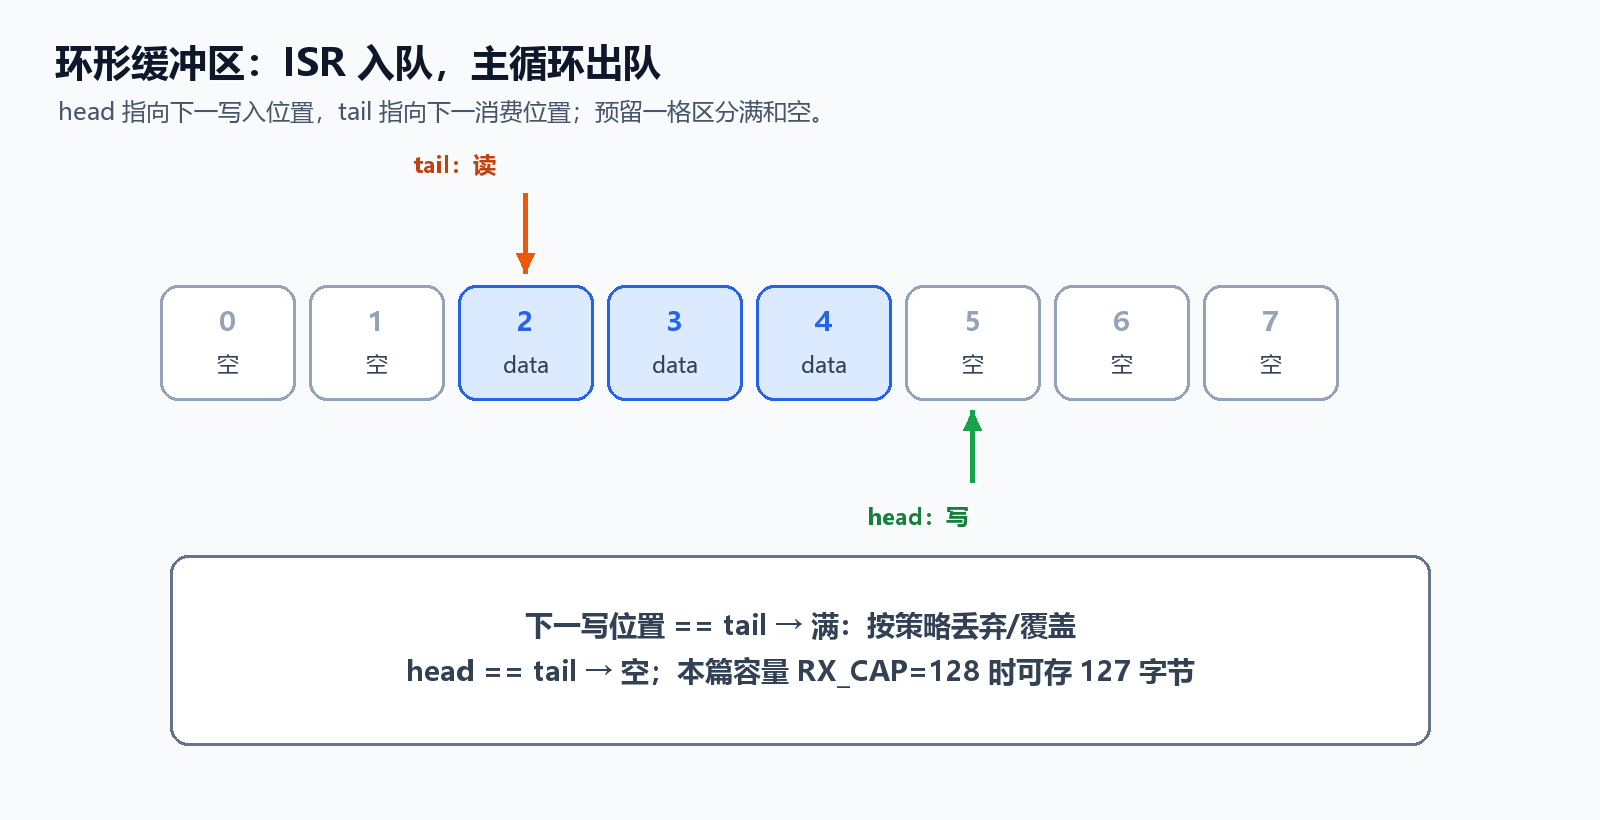

按连续 115200 baud/8N1 输入，127 字节可积压时间约为：

```text
127 / 11520 ≈ 11.024 ms
```

这是假设队列从空开始、ISR 都及时读取硬件的理想预算。主循环每次阻塞打印几十毫秒，队列仍可能溢出；如果 ISR 被屏蔽超过约一个字符帧，硬件数据缓冲又可能先出现 ORERR。软件缓冲大不等于能补回已经在硬件丢掉的字节。

初步容量可估为 `ceil(最大字节到达率 × 最长消费间隔) + 突发余量`，但必须同时满足**长期平均消费速率大于到达速率**。用流控、限制发送方、减少打印和扩大合理缓冲一起解决。

一旦出现丢失，本例不继续把残片拼成命令，而是通知解析器丢弃到下一 LF，重新建立边界。错误计数只表示本地检测到的事件数量，不等于线上全部错误的精确总数。


## 14. 主循环的安全行解析器

此函数片段需要 `<string.h>`，与第 12 节一起使用。接收行过长、含不允许的控制字节或发生 RX_LOSS 时，丢弃到下一 LF；尾部单个 CR 在确认 LF 后才去掉，避免把 `O\rN` 当成 ON。

```c
#define LINE_CAP 32U
typedef struct {
    char data[LINE_CAP];
    size_t len;
    bool discard;
} LineReader;

static bool line_feed(LineReader *r, uint8_t value)
{
    if (value == '\n') {
        if (r->discard) {
            r->len = 0U;
            r->discard = false;
            return false;
        }
        if (r->len != 0U && r->data[r->len - 1U] == '\r') {
            --r->len;
        }
        r->data[r->len] = '\0';
        r->len = 0U;                // 返回后需立即消费，下一字节会复用
        return true;
    }
    if (r->discard) { return false; }
    if ((value < 0x20U && value != '\r') || value > 0x7EU ||
        r->len >= LINE_CAP - 1U) {
        r->len = 0U;
        r->discard = true;
        return false;
    }
    r->data[r->len++] = (char)value;
    return false;
}
```

LF-only 行最多容纳 31 个内容字符；CRLF 行的 CR 也占一格，所以最多 30 个内容字符。本协议的 ON/OFF/STATUS 远小于上限。空行可由业务忽略。

收到丢失通知时执行 `r.len=0; r.discard=true`。不能把截断的长命令仍当作有效前缀执行；不允许把二进制含零数组直接送给这个文本解析器。


## 15. 串口控灯整合：ON / OFF / STATUS

这是一段**工程整合示例**，依赖前述初始化、队列、行解析器、发送函数、第 04 篇 `core_led_init/core_led_write`，以及已初始化的 `board_millis()`。不是包含启动/system/SPL 的独立 SDK 工程。各块合到一个独立实验，保留唯一 main 与 USART0 Handler。

```c
static void reply(const char *text)
{
    if (!usart0_write((const uint8_t *)text, strlen(text), 20U)) {
        // 项目可记录 tx_timeout；不要递归打印这个发送故障
    }
}

int main(void)
{
    // 项目必须先初始化 1ms 时基，为 board_millis() 提供计数
    core_led_init();
    nvic_priority_group_set(NVIC_PRIGROUP_PRE2_SUB2);
    usart0_init_115200();
    usart0_rx_irq_enable();
    bool led_on = false;
    LineReader reader = {0};

    while (1) {
        uint8_t value;
        RxResult result = rx_take(&value);
        if (result == RX_LOSS) {
            reader.len = 0U;
            reader.discard = true;
        } else if (result == RX_BYTE && line_feed(&reader, value)) {
            if (reader.data[0] == '\0') { continue; }
            if (strcmp(reader.data, "ON") == 0) {
                led_on = true;
                core_led_write(led_on);
                reply("OK ON\r\n");
            } else if (strcmp(reader.data, "OFF") == 0) {
                led_on = false;
                core_led_write(led_on);
                reply("OK OFF\r\n");
            } else if (strcmp(reader.data, "STATUS") == 0) {
                reply(led_on ? "LED=1\r\n" : "LED=0\r\n");
            } else {
                reply("ERR CMD\r\n");
            }
        }
        // 其他短任务；大量命令需 TX 队列/限速，不能靠扩大 RX 无限兜底
    }
}
```

一次发 `ON\nOFF\nSTATUS\n`，预期依次收到 `OK ON`、`OK OFF`、`LED=0`。分片发 `O`、`N\n` 仍只执行一次 ON；不发 LF 则不执行。

短回复采用阻塞发送便于入门。持续高负载时，回复流量可能大于请求流量，积压与溢出仍会发生；进阶改为统一 TX 队列、TBE IRQ 或批量 DMA。这个程序的可靠性边界由输入速率、IRQ 延迟和消费能力决定。


## 16. 多文件封装与回调职责

| 文件 | 建议职责 |
|---|---|
| usart0.h / usart0.c | 参数初始化、RX/TX 队列、收发接口 |
| gd32f4xx_it.c | 唯一硬件 Handler，调用短的驱动入口 |
| protocol.h / protocol.c | 行或二进制协议状态机、校验 |
| jdy33.c / gps.c | 模块业务和状态 |
| main.c | 调度、消费事件、应用动作 |

课程用 extern 把 ISR 需要的缓冲和标志引入另一个文件，理解声明与定义很重要。改进做法是把状态设为驱动文件的 static，只暴露 `serial_read/serial_write/serial_irq` 等接口，减少外部代码任意改队列下标。

函数叫 `on_usartX_recv()` 并不自动意味着它在主循环执行；关键是调用位置。如果 Handler 直接调用回调，回调仍处于 ISR 上下文。GPS 解析、浮点转换和桥接发送放到主循环，不因“封装成回调”就变成安全的短中断。


## 17. DMA：CPU 配置，硬件按请求搬运

DMA 是独立的搬运硬件，通过总线访问地址。CPU 配置起点、方向、宽度、数量、请求来源和模式，然后外设/DMA握手驱动传输；完成或错误时 CPU 再处理状态。

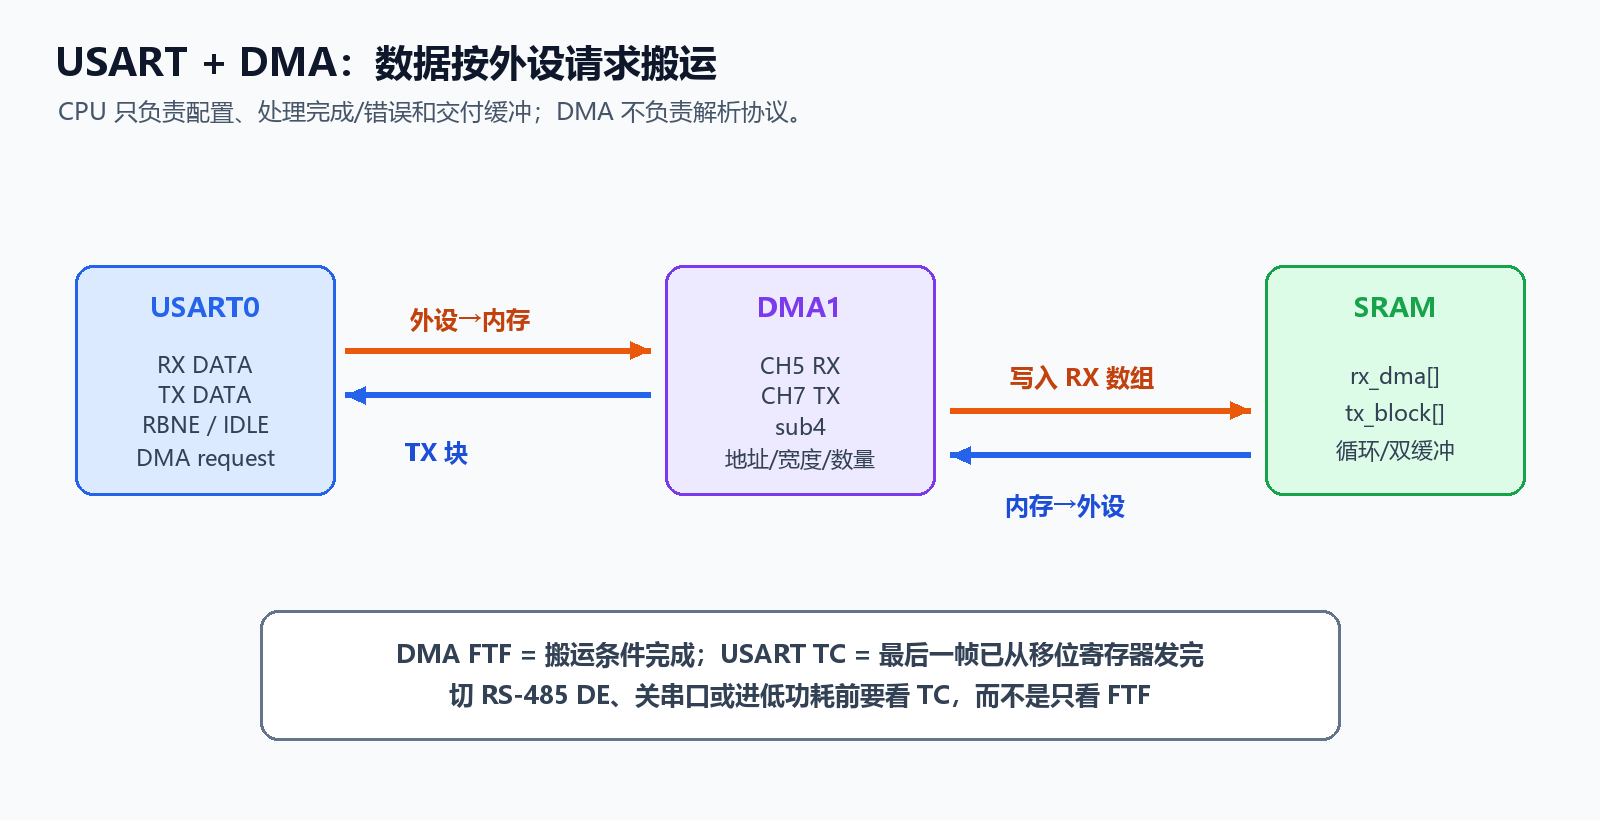

| 模式 | 源 → 目标 | 典型用途 |
|---|---|---|
| 内存到内存 | SRAM A → SRAM B | 批量复制，GD32F4xx 仅 DMA1 支持 |
| 内存到外设 | 发送数组 → USART DATA | 批量 UART 发送 |
| 外设到内存 | USART DATA → 接收数组 | 连续或固定长度接收 |

接收 DMA 配好并使能后，由 USART 的 DMA 请求直接驱动。课程“CPU 每次处理中断再通知 DMA”的概括不能理解为每个字节都必须经过 CPU Handler，否则丢掉了 DMA 的主要价值。

DMA 不解析 ON/OFF，不自动校验 NMEA，不自动添加 '\0'。它还与 CPU 和其他 DMA 竞争总线；“DMA 无需 CPU 逐字节参与”不等于配置、完成处理和并发控制都没有成本。


## 18. DMA0、DMA1、通道与 subperipheral

GD32F4xx 有 DMA0/DMA1，各 8 个通道、共 16 个。每个通道的 PERIEN/subperipheral 从固定映射表选择请求，不能把任意外设随意接到任意通道。

手册 3.4 的表 10-3（PDF 第 203 页）明确：

| USART0 请求 | 控制器 | 可用通道 | PERIEN / SPL 选择 |
|---|---|---|---|
| RX | DMA1 | CH2 或 CH5，选其一 | `100b` / `DMA_SUBPERI4` |
| TX | DMA1 | CH7 | `100b` / `DMA_SUBPERI4` |

本篇延续课程组合：**RX=DMA1/CH5/sub4，TX=DMA1/CH7/sub4**。不得同时启用 CH2 和 CH5 去响应同一个 USART0_RX 请求；手册禁止这种双通道竞争。

```c
dma_channel_subperipheral_select(DMA1, DMA_CH7, DMA_SUBPERI4);
```

只选对地址、没选对请求映射，UART DMA 仍可能不动。模块换 USART1/2 时需要重新查表，不能继续照搬 USART0 的 DMA1/CH5/CH7。

DMA 软件优先级有低/中/高/超高；相同软件级别时较小通道号优先。DMA 总线优先级和 NVIC 中断优先级属于不同机制，不能把二者混为一个“优先级”。


## 19. 地址、增长、宽度与 number

| 传输 | `periph_addr` 实际含义 | `memory0_addr` | 外设侧增长 | 内存侧增长 |
|---|---|---|---|---|
| UART TX | 目标 DATA 地址 | 源数组 | 禁止 | 允许 |
| UART RX | 源 DATA 地址 | 目标数组 | 禁止 | 允许 |
| 内存到内存 | 源内存地址 | 目标内存地址 | 按需求允许 | 按需求允许 |

“periph”字段是 DMA 的一个地址端口名称，**内存到内存时它装的是源内存地址，不能忽略**。向 USART 写入一串数据时，寄存器地址固定，数组地址按元素增长；增长步长由宽度/模式决定，并不永远是 1 字节。

普通 8N1 UART 选择 8 bit 宽度、number 为字节数量。通用地说，number/CNT 表示**传输项数**，与外设端宽度关联：100 项 × 16 bit 对应 200 字节，不是 100 字节。单次 DMA 控制计数最大为 65535 项。

启用 9 个有效数据位时，8 位数组无法保留第 9 位，需按手册选合适宽度与存储类型；不能把“所有 UART DMA 都用 uint8_t”当通用规则。

单数据模式使两端宽度一致；多数据模式支持 FIFO 和打包/拆包。**内存到内存只支持多数据模式**（手册 10.4.2/10.4.7），不要拿串口的 `dma_single_data_mode_init()` 配法直接复制到内存搬运实验。


## 20. 内存到内存实验的完整配置思路

课程希望通过 DMA 把 `src[1024]` 复制到 `dst[1024]`。这应先作为独立实验验证：

```text
选 DMA1 的空闲通道
→ 确认已停用，清历史标志
→ 使用多数据/FIFO配置
→ direction = MEMORY_TO_MEMORY
→ periph/source = src，memory/destination = dst
→ 两端8bit，地址均增长，number=1024
→ 不开循环、不需 USART 请求选择
→ 启用通道，等待完成或错误/超时
→ 确认CHEN已关闭，检查错误与剩余数量
→ 比较 src/dst 的1024个字节
```

这里的多数据初始化结构与 API 要按自己的 SPL 版本配置，本篇没有给出未经构建验证的“通吃库版本”完整 M2M 源文件。短数组可用 memcpy，DMA 适合批量/并行场景，不保证小块复制更快；两个地址范围不要重叠，不把 DMA 当作 memmove。

若 src 初始化为 `"hello"`，数组后面通常是零；只打印 `%s` 最多证明前面的字符串正常，不能证明 1024 字节都复制正确。使用 memcmp 或逐字节比较，并核对尾部哨兵未改变。

FTF 也可能因软件停用或特定错误条件产生；判断成功需一起看错误、剩余项数和通道状态，不能只看“有 FTF”。


## 21. UART DMA TX：一次发送一个块

以下是**启动阶段、只运行一次**的函数片段，依赖第 7 节 USART0 初始化和 `gd32f4xx_dma.c`。DMA1/CH7 必须是空闲资源；函数返回后由应用检查完成/错误状态，不能重复调用它来强行打断在途数据。

```c
static uint8_t tx_demo[] = "DMA hello\r\n"; // 放在可被DMA访问的SRAM

static void dma1_ch7_tx_demo_start(void)
{
    rcu_periph_clock_enable(RCU_DMA1);
    dma_deinit(DMA1, DMA_CH7);     // 独立实验初始状态，不用于抢占运行通道

    dma_single_data_parameter_struct cfg;
    dma_single_data_para_struct_init(&cfg);
    cfg.direction = DMA_MEMORY_TO_PERIPH;
    cfg.periph_addr = (uint32_t)(uintptr_t)&USART_DATA(USART0);
    cfg.periph_inc = DMA_PERIPH_INCREASE_DISABLE;
    cfg.memory0_addr = (uint32_t)(uintptr_t)tx_demo;
    cfg.memory_inc = DMA_MEMORY_INCREASE_ENABLE;
    cfg.periph_memory_width = DMA_PERIPH_WIDTH_8BIT;
    cfg.number = sizeof(tx_demo) - 1U;  // 不发送C字符串的末尾0
    cfg.priority = DMA_PRIORITY_HIGH;
    cfg.circular_mode = DMA_CIRCULAR_MODE_DISABLE;
    dma_single_data_mode_init(DMA1, DMA_CH7, &cfg);
    dma_channel_subperipheral_select(DMA1, DMA_CH7, DMA_SUBPERI4);

    usart_dma_transmit_config(USART0, USART_DENT_ENABLE);
    usart_flag_clear(USART0, USART_FLAG_TC);
    __DMB();                      // 发布内存内容，不能代替缓冲区所有权
    dma_channel_enable(DMA1, DMA_CH7);
}
```

`uintptr_t` 需要 `<stdint.h>`；目标为 32 位 MCU。结构字段、宽度宏、DMA 选择和 USART 标志 API 需要匹配目标头文件，此片段未在 SDK 编译。单数据模式两端采用相同 8 bit 宽度，DATA 外设允许的访问路径以手册/库为准。

连续请求不能每次都复位通道；应该有 `IDLE → BUSY → DONE/ERROR → IDLE` 状态，拒绝忙时重入，或把新数据排入队列。


## 22. DMA TX 的所有权、完成和重启

```text
调用方填写缓冲区 → TX队列取得所有权 → 启动DMA
→ DMA正常完成，源缓冲可按驱动契约释放
→ 如需切方向/关闭串口，继续等待USART TC
→ 清状态，开始下一块
```

异步 DMA 不能持有已经失效的栈变量地址。例如函数内 `char text[32]` 交给 DMA 后立即返回，栈内容可能被别的调用改写。静态数组不会失效，但也不能在 DMA 尚在读取时修改。用持久内存、拷贝到驱动队列或明确借用期限解决。

DMA 完成时 USART 缓冲/移位寄存器可能还有未发出的数据；源数组释放条件与 UART 线空闲条件不同。RS-485 的 DE 方向切换必须等正确清除过旧状态后的 TC，不能看到复位时 TC=1 就直接宣布新传输结束。

重配地址、number 或模式前：停用通道 → **等待 CHEN 实际为 0** → 检查错误和残余项 → 清对应标志 → 写新配置 → 启用。写了 disable 不等于总线/FIFO 立刻静止；等待应有时基超时，超时进入故障恢复，不能继续改活动通道。

UART 单字节 fputc 每次启动 DMA 并忙等，可能只增加配置成本。批量发送一段有限长度数据、让 CPU 同时做其他工作，更能体现 DMA 的作用。


## 23. UART DMA RX：固定长度与循环模式

接收配置和发送配置的方向相反：

```text
USART0 DATA（固定源） → DMA1 CH5 sub4 → rx_dma[]（增长目标）
```

固定长度/普通模式：number=256 时，接满 256 项再完成。只收到 10 字节，DMA 不会因为“暂时没新数据”就自动完成；在第 256 字节完成后若不及时重启，后续接收可能溢出。

循环模式：每圈自动重装数量并从缓冲区起点继续，适合连续输入。满圈后未消费的旧数据会被覆盖，**没有自动反压**。

下面是 RX **配置要点片段**，需补齐第 21 节式结构体初始化、DMA时钟/清标志/停止检查，保证发端在初始化时静默；它不能单独复制构成完整驱动：

```c
static uint8_t rx_dma[256];
// cfg 已由 dma_single_data_para_struct_init() 初始化
cfg.direction = DMA_PERIPH_TO_MEMORY;
cfg.periph_addr = (uint32_t)(uintptr_t)&USART_DATA(USART0);
cfg.periph_inc = DMA_PERIPH_INCREASE_DISABLE;
cfg.memory0_addr = (uint32_t)(uintptr_t)rx_dma;
cfg.memory_inc = DMA_MEMORY_INCREASE_ENABLE;
cfg.periph_memory_width = DMA_PERIPH_WIDTH_8BIT;
cfg.number = sizeof(rx_dma);
cfg.circular_mode = DMA_CIRCULAR_MODE_ENABLE;
dma_single_data_mode_init(DMA1, DMA_CH5, &cfg);
dma_channel_subperipheral_select(DMA1, DMA_CH5, DMA_SUBPERI4);
usart_interrupt_disable(USART0, USART_INT_RBNE); // 不让CPU逐字节抢读DATA
dma_channel_enable(DMA1, DMA_CH5);
usart_dma_receive_config(USART0, USART_DENR_ENABLE);
```

本模式与第 12 节的 CPU 接收二选一。循环 RX 还需专用 DMA HTF/FTF、USART IDLE/错误处理与消费状态；这些通知只用于唤醒/交付数据，完整命令仍由协议解析器判断。


## 24. IDLE + DMA：得到数据片段，不直接宣布消息完成

普通模式在允许停顿的协议中可采用：

```text
收到IDLE提示
→ 协调USART DMA请求与数据读取权
→ 停DMA并等CHEN=0，确保FIFO已按手册排空
→ 按STAT0→DATA要求清IDLE，识别尚未由DMA消费的尾字节
→ 用“配置数量 - 剩余数量”得到有效项数，并检查错误
→ 把有效块交给软件队列/切换另一个缓冲
→ 清DMA状态、重装接收、再解析消息
```

这是需要按目标硬件验证的驱动流程，不是“关 DMA、读一个寄存器、再开 DMA”就能保证无损。停止与重启之间存在接收窗口；连续发送可能需要流控、协议间隔或循环/双缓冲方案。CPU 为清 IDLE 读 DATA 时必须确认是否有合法尾字节，不能静默把它丢掉。

循环模式常用 `write_pos = (N - remaining) % N` 估算模 N 写位置，但仅凭位置无法区分“没新数据”与“正好覆盖了一整圈”。此外 CNT 与外设端搬运相关，计数改变不自动证明最后一项已经写稳到 RAM；内存屏障也不能让正在进行的 DMA 立刻完成。

连续流更容易采用 HTF/FTF 交付已完成的半块，并由单一消费状态协调 IDLE 尾段，避免重复/漏交。通知标志合并、消费者迟到或 DMA 绕回都需处理。不要给未经测量的 ISR/总线时序承诺“永不丢字节”。


## 25. 循环与双缓冲的处理预算

在 115200 baud/8N1 下，256 字节缓冲写满一圈约 **22.222 ms**，128 字节半块约 **11.111 ms**。使用半满/全满通知时，消费某半块的时间要小于 DMA 回来覆盖它的期限，并留给 ISR 延迟与其他工作余量。

双缓冲让 DMA 在 memory0/memory1 间切换；CPU 处理不被 DMA 当前访问的缓冲，所有权更清楚。但 CPU 处理超过下一次切换期限仍会丢数据，不能把双缓冲称为无限队列。

| 机制 | 解决的问题 | 仍需解决 |
|---|---|---|
| 单缓冲普通模式 | 固定长度块 | 重启窗口、少量数据何时交付 |
| 循环 DMA | 连续接收不频繁重启 | 绕回、覆盖、消费跟不上 |
| 双缓冲 | 分离当前写块和当前读块 | 截止时间、空闲尾段和队列容量 |
| 软件消息队列 | 已完成帧可延后业务处理 | 容量、丢弃策略和背压 |

缓冲区需放在 DMA 能访问的存储区域，满足宽度对齐、大小、生命周期与链接配置；不可假定 CPU 能读到的每个地址都能被 DMA 访问。移植到有数据缓存的 MCU 时还须处理缓存一致性，volatile 和 __DMB 不等于缓存维护。


## 26. JDY-33：UART 到蓝牙的透明通道

课程以 JDY-33 从机做透传桥接：

```text
电脑 ←USART0→ MCU ←另一组USART→ JDY-33 ←蓝牙→ 手机
```

从机表示由别的设备主动连接它，不表示它只能接收数据；建立连接后可双向收发。SPP 与 BLE 是不同连接方式，手机系统/应用要使用模块支持的方式；不要假定所有平台都支持经典 SPP。

SPP 是串行数据服务，不能因为模块支持 SPP 就认定它支持 A2DP 音频播放。页面给出的距离/速率属于模块条件下的标称或介绍，实际透传还受 UART 波特率、无线环境、连接参数和固件影响。

| 步骤 | 做什么 |
|---|---|
| 先单独测试 | USB-TTL ↔ 模块，核对供电、电平、当前波特率 |
| 查询固件 | 按模块手册发送 AT/版本查询，检查回复 |
| 配置名称等 | 使用当前固件的准确语法和行结束规则 |
| 手机连接 | 区分 BLE/SPP，选择正确应用和服务 |
| MCU 接入 | USART0 调试，另一 USART 与模块通信 |

课程 AT 表给出 AT、AT+VERSION、名称、波特率等指令。本篇没有核对模块附件的完整 AT 语法，不把 `AT+BAUD=115200` 等猜测写成可直接执行的事实。改波特率后，MCU 与模块两边必须在约定时点同步切换。


## 27. 双串口桥接与模块状态机

透明桥接应按**字节和长度**转发，而不是用 strlen 处理任意接收块。最简单的数据流是两个方向各自有独立 RX/TX 队列：

```text
USART0 RX队列 → 主循环 → USART1 TX队列
USART1 RX队列 → 主循环 → USART0 TX队列
```

使用 USART1 还是其他实例由板线确定；课程引脚表中 USART1 的 PA2/PA3 是候选组合，落地前核对实际芯片封装与 AF 表。不要把 USART0 的 DMA 通道复制给 USART1。

桥接两侧速率不同，缓存只能吸收短期突发。如果 PC 持续以 11520 byte/s 输入，而模组 UART 9600/8N1 只能消耗约 960 byte/s，积压约每秒增加 10560 字节，任何有限队列最终都会满。需限速、流控或应用确认；不能只增大数组。

AT 控制建议状态机：`未连接 → 发查询/配置 → 等待匹配回复或超时 → 透传 → 断开恢复`。区分 AT 回应、连接状态提示与用户载荷，超时/重试有上限。ISR 不做另一串口的阻塞发送，也不在转发方向混入调试 printf。


## 28. GPS：先校验 NMEA 句子，再提取 RMC

课程 GPS 页展示了约 9600 baud 的 NMEA 文本，包括 RMC/GGA/GSV 等。具体输出频率与语句可配置；“能收到句子”不等于“已经有效定位”，定位状态必须从报文判断。

常见结构：

```text
$ + talker/type + 逗号分隔字段 + *HH + CR LF
```

`HH` 是从 `$` 之后到 `*` 之前所有字符逐字节异或的两位十六进制值。先组完整行，限制最大长度，校验，再分字段；需要保留连续逗号形成的空字段，不能用会跳过空 token 的方法改变字段位置。

下面是校验函数片段：传入**已移除 CRLF 的计数数组**，它不要求额外 '\0'，需要 `<stdbool.h>`、`<stdint.h>`、`<stddef.h>`：

```c
static int hex_nibble(char ch)
{
    if (ch >= '0' && ch <= '9') { return ch - '0'; }
    if (ch >= 'A' && ch <= 'F') { return ch - 'A' + 10; }
    if (ch >= 'a' && ch <= 'f') { return ch - 'a' + 10; }
    return -1;
}

static bool nmea_checksum_ok(const char *line, size_t len)
{
    if (line == NULL || len < 5U || line[0] != '$') { return false; }
    uint8_t sum = 0U;
    size_t star = 1U;
    while (star < len && line[star] != '*') {
        uint8_t ch = (uint8_t)line[star++];
        if (ch < 0x20U || ch > 0x7EU) { return false; }
        sum ^= ch;
    }
    if (star + 3U != len) { return false; }
    int hi = hex_nibble(line[star + 1U]);
    int lo = hex_nibble(line[star + 2U]);
    return hi >= 0 && lo >= 0 && sum == (uint8_t)((hi << 4) | lo);
}
```

这个函数只验格式/异或值，不能代替定位状态、字段数、日期范围和坐标合法性检查。GPS 单独用更大的有限行缓冲（如 256 字节）并明确超长丢弃策略，不能直接用第 14 节的 32 字节命令缓冲接整条 RMC。

课程页面名为 NEO6M，但示例出现 GN/BD talker 前缀；仅凭标题不能确认实际模组型号或支持的星座。以模块标签、版本查询与厂商手册为准，也不要把 GN 前缀解释成“一定挑选所有星座中最好的一颗”。解析可按支持范围识别 GPRMC/GNRMC 等，不能无条件假定都叫 GNRMC。


## 29. RMC 的时间、有效状态、经纬度与坐标系

用课程给出的同一组数值作为计算示例：

```text
$GNRMC,094541.000,A,4003.54515,N,11620.24596,E,0.00,0.00,130625,,,A*71
```

| 字段 | 例子 | 含义 |
|---|---|---|
| UTC 时间 | 094541.000 | 09:45:41 UTC |
| 状态 | A | 有效；V 表示无效，不更新有效位置 |
| 纬度及半球 | 4003.54515,N | 40 度 03.54515 分，北纬 |
| 经度及半球 | 11620.24596,E | 116 度 20.24596 分，东经 |
| 地面速率 | 0.00 | 单位为节，换 m/s 约乘 0.514444 |
| UTC 日期 | 130625 | 示例解释为 2025-06-13；世纪策略由项目明确 |

度分转十进制度：

```text
degrees = floor(raw / 100)
minutes = raw - degrees × 100
decimal = degrees + minutes / 60
S/W 半球再取负号

4003.54515 → 40 + 3.54515/60  ≈ 40.0590858333°
11620.24596 → 116 + 20.24596/60 ≈ 116.3374326667°
```

课程说明段有一处把纬度换为 4003.54151；本篇统一使用报文里的 4003.54515，不能把这两个数值的结果混用。分必须在 [0,60)，纬度在 [-90,90]、经度在 [-180,180]；空字段或不完整数值拒绝更新。

北京时间为 UTC+8，09:45:41 → 17:45:41；18:00 UTC 加 8 小时需要连带日期加一天，月底、闰年和年末一起处理，不能只对小时 `%24`。GPS 灯状态仅作模块辅助指示，不用灯闪烁替代报文的有效定位判断。

GNSS 常见输出使用 WGS84，国内地图可能要求 GCJ02/BD09；展示前确认坐标系统，保留原始坐标来源和转换标识，避免对同一坐标重复转换。本例坐标只是课程报文算例，没有执行真实定位或向地图服务提交坐标。


## 30. 常见问题与验收顺序

| 现象 | 优先检查 |
|---|---|
| 没有 COM 口 | USB 数据线、DAPLink/USB-TTL枚举、电脑驱动与端口占用 |
| 全部无输出 | USART实例、RCU时钟、PA9/PA10 AF7、TEN/UEN、工具端口 |
| 英文也乱码 | 电平、波特率、时钟、字长/校验/停止位、接地 |
| 英文正常中文乱码 | 编码和工具显示模式 |
| RX 中断不进 | REN、RBNEIE、NVIC、启动向量与唯一 Handler |
| ISR 连续重入 | 源标志清除顺序、ORERR等未处理 |
| 发 ON 不执行 | 文本/HEX 模式、是否发 LF、大小写、丢失重同步 |
| DMA 不动 | 控制器/通道/subperi、方向/地址、DMA请求允许、CHEN |
| DMA 部分错乱 | 生命周期、活动缓冲被改写、宽度/number/地址增长 |
| DMA TX 尾部缺字 | 过早关串口/切DE，未等待正确的TC |
| 连续输入丢字节 | IRQ延迟、队列满、DMA覆盖、持续吞吐不足 |
| 蓝牙只有一个方向通 | 两端波特率、角色/服务、线路、应用协议/发送权限 |
| GPS 收到信息却无位置 | RMC状态、校验、空字段、天线/环境与定位等待 |

验收顺序：先做 USB-TTL/PC 简单收发，再测 RX 队列和分片消息，再做 DMA 块传输，最后接模块；每一步记录实际参数和错误计数。

动手练习：

1. 用逻辑分析仪测 115200/8N1 的 0x55，比较 bit 宽与字符帧宽。
2. 分次发 `O`、`N\n`；一次发 `ON\nOFF\n`；确认消息拼接和分离正确。
3. 输入超过行上限、含0字节、无LF、连续CR；确认不会执行截断命令。
4. 暂停主循环，制造RX队列满；恢复后必须丢弃到下一个LF再接受新命令。
5. DMA TX 发送带0字节的计数数组，按 HEX 模式核对长度与尾部；比较FTF和TC时刻。
6. 固定长度 RX 只发10字节，解释为何 number=256 不会立即FTF；再试半满/全满通知。
7. 桥接不同速率的两端，测出缓存满的时间，设计输入限速/流控。
8. 修改 RMC 一个字符、截短尾部校验或将状态改V；校验/语义检查应拒绝更新位置。

这些是待执行的硬件验收项目，本次没有把预期行为写成实测结果。


## 31. 自测答案与十二篇路线

| 问题 | 参考答案 |
|---|---|
| 115200/8N1 的有效字节率？ | 连续无间隙时11520 byte/s，不是115200 byte/s |
| 为什么 TBE 不等于 TC？ | 数据缓冲可以空，而移位寄存器仍在发送 |
| DMA FTF 是否能切 RS-485 DE？ | 不能直接切，需等待最后数据真正完成的USART TC |
| IDLE 是否证明 ON 已完整？ | 不能，停顿可能在O与N中间；按应用协议组帧 |
| RX ring[128] 留一格时容量？ | 127字节 |
| 内存到内存的 periph_addr 能忽略吗？ | 不能，它是源内存地址；DMA1且多数据模式 |
| UART RX 两端哪个地址增长？ | DATA源固定，目标数组增长 |
| 16bit宽度的100项是多少字节？ | 200字节 |
| volatile 能防 DMA 覆盖吗？ | 不能，需所有权、时限和缓冲策略 |
| 4003.54515 能直接作纬度吗？ | 不能，它是度分格式，换算约40.0590858333° |
| GPS数据校验通过就能用吗？ | 还需状态A、字段/数值合法和时间有效性检查 |

| 编号 | 笔记主题 |
|---|---|
| 01 | C语言核心语法与函数 |
| 02 | C语言指针与内存 |
| 03 | 单片机入门与开发环境 |
| 04 | GPIO与基础外设控制 |
| 05 | 中断与定时器 |
| **06** | **串口、DMA与通信模块（本篇）** |
| 07 | 实时时钟与系统管理 |
| 08 | I2C与SPI通信 |
| 09 | ADC与传感器采集 |
| 10 | 存储器与文件系统 |
| 11 | 屏幕显示与触摸驱动 |
| 12 | LVGL图形界面开发 |

一页复习：**接线与电平 → 参数与时钟 → 收发标志 → 缓冲所有权 → 消息边界 → 错误恢复 → 模块业务。**下一篇继续 RTC、看门狗与系统管理，把通信和时间基连接到更稳定的设备运行流程。


## 32. 课程来源索引与核对边界

阅读日期：2026-10-12。

| 分组 | 页面 |
|---|---|
| 串口原理与引脚 | [USART通信原理](https://www.yuque.com/xxcls/mcu/chn7uap176of89n1)、[GD32F4串口引脚查询](https://www.yuque.com/xxcls/mcu/ptyr9z4ihbleqcne)、[GD32F4复用功能查询](https://www.yuque.com/xxcls/mcu/skbpo4wuac3obtpx) |
| 串口驱动 | [串口发送](https://www.yuque.com/xxcls/mcu/cigm1snyex4yzun0)、[串口接收](https://www.yuque.com/xxcls/mcu/sq69kadnuaq2905x)、[串口模板代码](https://www.yuque.com/xxcls/mcu/zota2adwgx9ouaev)、[串口驱动封装](https://www.yuque.com/xxcls/mcu/argebttsvpwepe1d) |
| DMA | [DMA](https://www.yuque.com/xxcls/mcu/lggn8u49u078nbka)、[GD32F4 DMA功能查询](https://www.yuque.com/xxcls/mcu/ugzggoqd5h7yklwy)、[DMA内存到内存](https://www.yuque.com/xxcls/mcu/uzpr9fcvk6asmczx)、[DMA内存到外设](https://www.yuque.com/xxcls/mcu/toedrbmr5b8f6ply)、[DMA外设到内存](https://www.yuque.com/xxcls/mcu/wvmszwu272kgu0tg) |
| 通信模块 | [JDY-33蓝牙通信模块](https://www.yuque.com/xxcls/mcu/fggf42qpbonu6avl)、[NEO6M GPS模块](https://www.yuque.com/xxcls/mcu/gv4vg18ggzfg66tp) |
| 官方参考 | [GD32F4xx User Manual 下载](https://gd32mcu.com/download/down/document_id/98/path_type/1)、[已保存的手册3.4](C:/Users/23224/Desktop/stack-blueprint/work/mcu-note05-source/GD32F4xx_User_Manual.pdf) |

手册按 PDF 页序（从1开始）核对：

| 内容 | 重点页 |
|---|---|
| DMA能力、方向和外设握手 | 199～202 |
| DMA0/1请求映射表10-2/10-3 | 203（另视觉核对） |
| 宽度/计数、单/多数据、循环/双缓冲 | 204、206～211 |
| 完成、停止、重配、错误和标志清除 | 212～217、222～225 |
| USART能力、字符格式与时钟 | 518～520（519另视觉核对） |
| TBE/TC、接收与DMA访问 | 521～525 |
| STAT0/DATA和配置寄存器 | 534～537（535另视觉核对） |

代码来源与验证说明：14页可访问正文和部分可见短代码，不代表完整课程工程/模组手册已核对；部分引脚/AT表为页面图中的可访问文字，实际模块语法与扩展引脚仍以对应资料为准。环形队列、LF协议、超时发送与NMEA校验是本篇重写补充。`code_examples_compiled=false`、`hardware_run=false`；真实工程需匹配头文件、启动文件、SPL和板级电路后编译与测量。
